# Decision trees: entropy, Gini impurity, and information gain

This notebook follows the decision-tree development in Chapter 3.

The goals are to:

1. compute **entropy** and **Gini impurity** directly from class counts;
2. visualize both impurity measures;
3. represent the muffin training data explicitly;
4. use **lists of row IDs** to show exactly which examples belong to a node;
5. compute the information gain of candidate splits by hand-like code.

The implementation is deliberately simple. It does not use a decision-tree library.

In [1]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

try:
    from mlbook_style import apply_style, COLORS
    apply_style()
except ImportError:
    COLORS = {
        "model_1": "#0072B2",
        "model_2": "#CC79A7",
    }

pd.set_option("display.max_rows", 30)
pd.set_option("display.width", 120)

Suppose a node contains examples from classes with proportions

$$
p_1,\ldots,p_C.
$$

The **entropy** of the node is

$$
H(S)=-\sum_{c=1}^{C} p_c\log_2 p_c.
$$

The **Gini impurity** is

$$
G(S)=1-\sum_{c=1}^{C}p_c^2.
$$

In [2]:
def entropy_from_counts(counts):
    """Entropy from a sequence of class counts."""
    total = sum(counts)
    if total == 0:
        return 0.0

    h = 0.0
    for count in counts:
        if count == 0:
            continue
        p = count / total
        h -= p * math.log2(p)
    return h


def gini_from_counts(counts):
    """Gini impurity from a sequence of class counts."""
    total = sum(counts)
    if total == 0:
        return 0.0

    return 1.0 - sum((count / total) ** 2 for count in counts)

**Check.** What are entropy and Gini impurity for a pure binary node?

<details>
<summary><strong>Answer</strong></summary>

Both are 0. There is no class mixture in a pure node.

</details>

In [3]:
examples = {
    "8 YES, 0 NO": [8, 0],
    "6 YES, 2 NO": [6, 2],
    "4 YES, 4 NO": [4, 4],
}

for name, counts in examples.items():
    print(
        f"{name:12s}  "
        f"entropy = {entropy_from_counts(counts):.3f}   "
        f"Gini = {gini_from_counts(counts):.3f}"
    )

8 YES, 0 NO   entropy = 0.000   Gini = 0.000
6 YES, 2 NO   entropy = 0.811   Gini = 0.375
4 YES, 4 NO   entropy = 1.000   Gini = 0.500


## 2. Entropy and Gini impurity for binary classification

For a binary target, let \(p\) be the proportion of one class. The other class has proportion \(1-p\).

As in the book, we look first at **entropy** and then at **Gini impurity**.

**Predict.** Where should both curves attain their maximum?

<details>
<summary><strong>Answer</strong></summary>

At \(p=0.5\), where the two classes are equally represented.

</details>

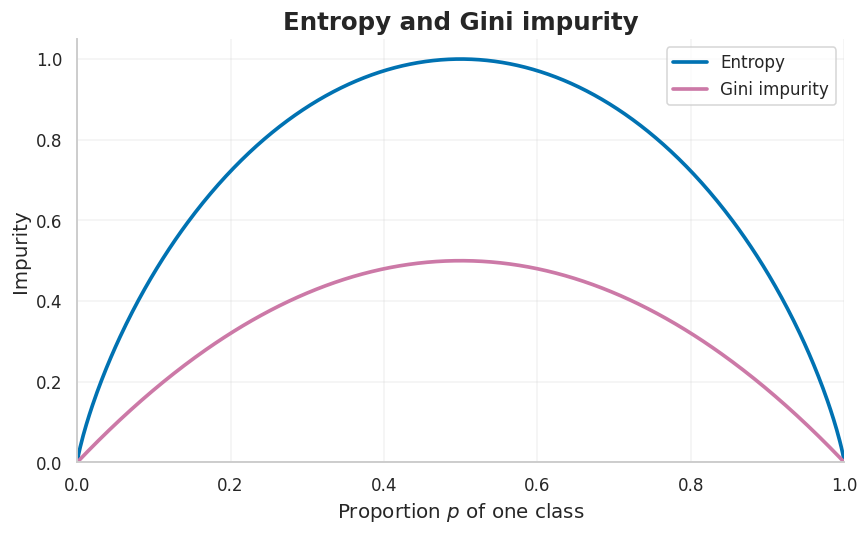

In [4]:
p = np.linspace(0, 1, 501)

entropy_values = np.array([
    entropy_from_counts([x, 1 - x]) for x in p
])

gini_values = np.array([
    gini_from_counts([x, 1 - x]) for x in p
])

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    p,
    entropy_values,
    label="Entropy",
    color=COLORS.get("model_1", None),
)
ax.plot(
    p,
    gini_values,
    label="Gini impurity",
    color=COLORS.get("model_2", None),
)

ax.set_xlabel("Proportion $p$ of one class")
ax.set_ylabel("Impurity")
ax.set_title("Entropy and Gini impurity")
ax.set_xlim(0, 1)
ax.set_ylim(bottom=0)
ax.legend()

plt.show()

**Takeaway.** Entropy and Gini impurity have different numerical scales, but similar qualitative behavior: pure nodes have low impurity and evenly mixed nodes have high impurity.

## 3. The muffin training data

The data are hard coded below. The DataFrame index is the muffin **ID**, so a list such as

```python
[1, 4, 8]
```

means that we are working with exactly those three training examples.

This makes the subsets used in information-gain calculations visible.

In [5]:
data = [
    # ID, Weekend, Time,       Flavor,       Size,  Sold quickly
    (1,   "no",    "morning",   "chocolate",  "small", "YES"),
    (2,   "yes",   "afternoon", "vanilla",    "large", "NO"),
    (3,   "no",    "morning",   "strawberry", "small", "NO"),
    (4,   "yes",   "morning",   "chocolate",  "large", "YES"),
    (5,   "no",    "lunch",     "vanilla",    "small", "NO"),
    (6,   "yes",   "afternoon", "strawberry", "large", "NO"),
    (7,   "no",    "afternoon", "chocolate",  "small", "YES"),
    (8,   "yes",   "morning",   "vanilla",    "small", "YES"),
    (9,   "no",    "lunch",     "strawberry", "large", "NO"),
    (10,  "yes",   "lunch",     "chocolate",  "small", "YES"),
    (11,  "no",    "afternoon", "vanilla",    "large", "NO"),
    (12,  "yes",   "afternoon", "strawberry", "small", "NO"),
    (13,  "no",    "lunch",     "chocolate",  "large", "YES"),
    (14,  "yes",   "lunch",     "vanilla",    "small", "NO"),
    (15,  "no",    "morning",   "vanilla",    "small", "YES"),
    (16,  "yes",   "afternoon", "chocolate",  "large", "YES"),
]

df = pd.DataFrame(
    data,
    columns=["ID", "Weekend", "Time", "Flavor", "Size", "Sold quickly"],
).set_index("ID")

df

,Weekend,Time,Flavor,Size,Sold quickly
ID,,,,,
1,no,morning,chocolate,small,YES
2,yes,afternoon,vanilla,large,NO
3,no,morning,strawberry,small,NO
4,yes,morning,chocolate,large,YES
5,no,lunch,vanilla,small,NO
6,yes,afternoon,strawberry,large,NO
7,no,afternoon,chocolate,small,YES
8,yes,morning,vanilla,small,YES
9,no,lunch,strawberry,large,NO


In [6]:
all_ids = df.index.tolist()
all_ids

[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]

## 4. Computing impurity from a list of selected IDs

The next functions receive a list of muffin IDs. They first select those rows and then compute the class counts.

In [7]:
TARGET = "Sold quickly"


def selected_data(ids):
    """Return exactly the rows identified by `ids`."""
    return df.loc[ids]


def class_counts(ids):
    """Return YES/NO counts for selected row IDs."""
    counts = selected_data(ids)[TARGET].value_counts()
    return [
        int(counts.get("YES", 0)),
        int(counts.get("NO", 0)),
    ]


def entropy(ids):
    return entropy_from_counts(class_counts(ids))


def gini(ids):
    return gini_from_counts(class_counts(ids))

In [8]:
root_ids = all_ids

print("Selected IDs:", root_ids)
print("Class counts [YES, NO]:", class_counts(root_ids))
print("Entropy:", entropy(root_ids))
print("Gini impurity:", gini(root_ids))

Selected IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Class counts [YES, NO]: [8, 8]
Entropy: 1.0
Gini impurity: 0.5


**Check.** Why is the root entropy equal to 1?

<details>
<summary><strong>Answer</strong></summary>

The root contains 8 YES and 8 NO examples. A balanced binary node has maximal entropy, \(H=1\).

</details>

## 5. A split as lists of selected IDs

A categorical split partitions the current list of IDs into one list for each observed feature value.

In [9]:
def split_ids(ids, feature):
    """Return {feature_value: [IDs]} for the selected rows."""
    subset = selected_data(ids)
    return {
        value: subset.index[subset[feature] == value].tolist()
        for value in subset[feature].unique()
    }


flavor_split = split_ids(root_ids, "Flavor")

for value, ids in flavor_split.items():
    print(f"{value:10s}: {ids}")

chocolate : [1, 4, 7, 10, 13, 16]
vanilla   : [2, 5, 8, 11, 14, 15]
strawberry: [3, 6, 9, 12]


For `Flavor`, the split is therefore represented explicitly by three lists of training-example IDs. We can inspect any one of them directly.

In [10]:
vanilla_ids = flavor_split["vanilla"]

print("Vanilla IDs:", vanilla_ids)
selected_data(vanilla_ids)

Vanilla IDs: [2, 5, 8, 11, 14, 15]


,Weekend,Time,Flavor,Size,Sold quickly
ID,,,,,
2,yes,afternoon,vanilla,large,NO
5,no,lunch,vanilla,small,NO
8,yes,morning,vanilla,small,YES
11,no,afternoon,vanilla,large,NO
14,yes,lunch,vanilla,small,NO
15,no,morning,vanilla,small,YES


## 6. Weighted impurity and information gain

If a split on feature $A$ produces subsets $S_1,\ldots,S_k$, the impurity after the split is

$$
I(S\mid A)
=
\sum_{j=1}^{k}
\frac{|S_j|}{|S|}
I(S_j).
$$

The reduction in impurity is

$$
\Delta I(S,A)=I(S)-I(S\mid A).
$$

When entropy is used, this reduction is called **information gain**:

$$
IG(S,A)=H(S)-H(S\mid A).
$$


In [11]:
def weighted_impurity(ids, feature, impurity_function):
    groups = split_ids(ids, feature)
    total = len(ids)

    result = 0.0
    for value, child_ids in groups.items():
        weight = len(child_ids) / total
        result += weight * impurity_function(child_ids)

    return result


def information_gain(ids, feature):
    parent_entropy = entropy(ids)
    child_entropy = weighted_impurity(ids, feature, entropy)
    return parent_entropy - child_entropy


def gini_gain(ids, feature):
    parent_gini = gini(ids)
    child_gini = weighted_impurity(ids, feature, gini)
    return parent_gini - child_gini

**Predict.** Which root feature should have the largest information gain: `Weekend`, `Time`, `Flavor`, or `Size`?

<details>
<summary><strong>Answer</strong></summary>

`Flavor`. Chocolate is already pure YES and strawberry is pure NO, leaving only the vanilla examples mixed.

</details>

In [12]:
FEATURES = ["Weekend", "Time", "Flavor", "Size"]

root_results = pd.DataFrame(
    {
        "Information gain": [
            information_gain(root_ids, feature)
            for feature in FEATURES
        ],
        "Gini reduction": [
            gini_gain(root_ids, feature)
            for feature in FEATURES
        ],
    },
    index=FEATURES,
)

root_results.round(3)

,Information gain,Gini reduction
Weekend,0.000,0.000
Time,0.127,0.083
Flavor,0.656,0.333
Size,0.011,0.008


## 7. Inspecting one information-gain calculation

The helper below prints the actual ID lists, class counts, entropy of each child, and its weight in the weighted average. This is the same arithmetic as in the worked example in the book.

In [13]:
def explain_information_gain(ids, feature):
    parent_h = entropy(ids)
    groups = split_ids(ids, feature)

    print(f"Parent IDs: {ids}")
    print(f"Parent counts [YES, NO]: {class_counts(ids)}")
    print(f"Parent entropy: {parent_h:.3f}\n")

    weighted_h = 0.0

    for value, child_ids in groups.items():
        counts = class_counts(child_ids)
        h = entropy(child_ids)
        weight = len(child_ids) / len(ids)
        contribution = weight * h
        weighted_h += contribution

        print(f"{feature} = {value}")
        print(f"  IDs: {child_ids}")
        print(f"  counts [YES, NO]: {counts}")
        print(f"  entropy: {h:.3f}")
        print(f"  weight: {len(child_ids)}/{len(ids)} = {weight:.3f}")
        print(f"  weighted contribution: {contribution:.3f}\n")

    gain = parent_h - weighted_h

    print(f"Weighted entropy after split: {weighted_h:.3f}")
    print(f"Information gain: {parent_h:.3f} - {weighted_h:.3f} = {gain:.3f}")

In [14]:
explain_information_gain(root_ids, "Flavor")

Parent IDs: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16]
Parent counts [YES, NO]: [8, 8]
Parent entropy: 1.000

Flavor = chocolate
  IDs: [1, 4, 7, 10, 13, 16]
  counts [YES, NO]: [6, 0]
  entropy: 0.000
  weight: 6/16 = 0.375
  weighted contribution: 0.000

Flavor = vanilla
  IDs: [2, 5, 8, 11, 14, 15]
  counts [YES, NO]: [2, 4]
  entropy: 0.918
  weight: 6/16 = 0.375
  weighted contribution: 0.344

Flavor = strawberry
  IDs: [3, 6, 9, 12]
  counts [YES, NO]: [0, 4]
  entropy: 0.000
  weight: 4/16 = 0.250
  weighted contribution: 0.000

Weighted entropy after split: 0.344
Information gain: 1.000 - 0.344 = 0.656


## 8. The second split: only the vanilla IDs

TDIDT now works only with the examples that reached the vanilla node. The node is represented by the list `vanilla_ids`.

In [15]:
print("Vanilla IDs:", vanilla_ids)
print("Class counts [YES, NO]:", class_counts(vanilla_ids))
print("Entropy:", round(entropy(vanilla_ids), 3))

selected_data(vanilla_ids)

Vanilla IDs: [2, 5, 8, 11, 14, 15]
Class counts [YES, NO]: [2, 4]
Entropy: 0.918


,Weekend,Time,Flavor,Size,Sold quickly
ID,,,,,
2,yes,afternoon,vanilla,large,NO
5,no,lunch,vanilla,small,NO
8,yes,morning,vanilla,small,YES
11,no,afternoon,vanilla,large,NO
14,yes,lunch,vanilla,small,NO
15,no,morning,vanilla,small,YES


**Predict.** Among the remaining features `Weekend`, `Time`, and `Size`, which one should produce the largest information gain for the vanilla subset?

<details>
<summary><strong>Answer</strong></summary>

`Time`. With the corrected ID 11, morning contains only YES examples, while lunch and afternoon contain only NO examples.

</details>

In [16]:
remaining_features = ["Weekend", "Time", "Size"]

vanilla_results = pd.DataFrame(
    {
        "Information gain": [
            information_gain(vanilla_ids, feature)
            for feature in remaining_features
        ],
        "Gini reduction": [
            gini_gain(vanilla_ids, feature)
            for feature in remaining_features
        ],
    },
    index=remaining_features,
)

vanilla_results.round(3)

,Information gain,Gini reduction
Weekend,0.000,0.000
Time,0.918,0.444
Size,0.252,0.111


In [17]:
explain_information_gain(vanilla_ids, "Time")

Parent IDs: [2, 5, 8, 11, 14, 15]
Parent counts [YES, NO]: [2, 4]
Parent entropy: 0.918

Time = afternoon
  IDs: [2, 11]
  counts [YES, NO]: [0, 2]
  entropy: 0.000
  weight: 2/6 = 0.333
  weighted contribution: 0.000

Time = lunch
  IDs: [5, 14]
  counts [YES, NO]: [0, 2]
  entropy: 0.000
  weight: 2/6 = 0.333
  weighted contribution: 0.000

Time = morning
  IDs: [8, 15]
  counts [YES, NO]: [2, 0]
  entropy: 0.000
  weight: 2/6 = 0.333
  weighted contribution: 0.000

Weighted entropy after split: 0.000
Information gain: 0.918 - 0.000 = 0.918


**Takeaway.** Information gain is always computed relative to the examples that reach the current node. At the root we use all 16 IDs; at the vanilla node we use only the six vanilla IDs.

## 9. Optional: compare entropy and Gini choices

Both impurity measures can be used to rank candidate splits. They need not always rank splits identically, but for this small example they can be compared directly.

In [18]:
comparison = root_results.copy()
comparison["IG rank"] = comparison["Information gain"].rank(ascending=False, method="min").astype(int)
comparison["Gini rank"] = comparison["Gini reduction"].rank(ascending=False, method="min").astype(int)

comparison.sort_values("Information gain", ascending=False).round(3)

,Information gain,Gini reduction,IG rank,Gini rank
Flavor,0.656,0.333,1,1
Time,0.127,0.083,2,2
Size,0.011,0.008,3,3
Weekend,0.000,0.000,4,4


**Think.** Why do we use the *reduction* in impurity rather than simply choosing the child node with the lowest impurity?

<details>
<summary><strong>Answer</strong></summary>

A split creates several children, not one. We must evaluate the whole partition, weighting each child by how many training examples it contains, and compare that result with the impurity of the parent.

</details>